In [12]:
import sys, os, time, json, itertools
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import xgboost as xgb

ROOT = os.path.abspath("..")
sys.path.append(ROOT)
DATA = os.path.join(ROOT, "data", "processed", "loans_clean.parquet")
FIG = os.path.join(ROOT, "reports", "figures")

from src.data import load_splits, for_trees
from src.metrics import evaluate

tr, va, te = load_splits(DATA)
((Xtr, ytr), (Xva, yva), (Xte, yte)), feats = for_trees(tr, va, te)
print(Xtr.shape, Xva.shape, Xte.shape, "| features:", len(feats))

(60298, 68) (12921, 68) (12922, 68) | features: 68


In [13]:
def make(depth=6, lr=0.05, mcw=1):
    return xgb.XGBClassifier(
        n_estimators=2000, learning_rate=lr, max_depth=depth, min_child_weight=mcw,
        subsample=0.8, colsample_bytree=0.8, tree_method="hist", enable_categorical=True,
        early_stopping_rounds=50, eval_metric="auc", random_state=42, n_jobs=-1)

base = make()
base.fit(Xtr, ytr, eval_set=[(Xva, yva)], verbose=False)
print("best iteration:", base.best_iteration)
print("val:", evaluate(yva, base.predict_proba(Xva)[:, 1]))

best iteration: 105
val: {'rmse': 0.3660420240742103, 'mae': 0.2678463369796482, 'r2': 0.12086344911916858, 'roc_auc': 0.7386053999083819, 'pr_auc': 0.40275749421626106, 'ks': 0.3488401212227539}


In [14]:
rows = []
for depth, lr, mcw in itertools.product([3, 5, 7], [0.03, 0.1], [1, 10]):
    m = make(depth, lr, mcw)
    t0 = time.time()
    m.fit(Xtr, ytr, eval_set=[(Xva, yva)], verbose=False)
    rows.append(dict(depth=depth, lr=lr, mcw=mcw, iters=m.best_iteration,
                     val_auc=evaluate(yva, m.predict_proba(Xva)[:, 1])["roc_auc"],
                     secs=round(time.time() - t0, 1)))
res = pd.DataFrame(rows).sort_values("val_auc", ascending=False)
res

,depth,lr,mcw,iters,val_auc,secs
0,3,0.03,1,508,0.740228,15.8
1,3,0.03,10,515,0.739930,11.9
2,3,0.10,1,102,0.739160,5.2
3,3,0.10,10,110,0.739084,5.4
5,5,0.03,10,213,0.737842,10.2
4,5,0.03,1,287,0.737796,12.6
9,7,0.03,10,189,0.737588,11.5
11,7,0.10,10,33,0.736352,4.5
6,5,0.10,1,97,0.736266,6.1
7,5,0.10,10,86,0.736261,5.5


In [15]:
best = res.iloc[0]
final = make(int(best.depth), float(best.lr), int(best.mcw))
t0 = time.time()
final.fit(Xtr, ytr, eval_set=[(Xva, yva)], verbose=False)
train_secs = round(time.time() - t0, 1)

result = {
    "framework": "XGBoost",
    "params": {"max_depth": int(best.depth), "learning_rate": float(best.lr), "min_child_weight": int(best.mcw)},
    "train_seconds": train_secs,
    "val": evaluate(yva, final.predict_proba(Xva)[:, 1]),
    "test": evaluate(yte, final.predict_proba(Xte)[:, 1]),
}
print(json.dumps(result, indent=2))
with open(os.path.join(ROOT, "reports", "results_xgboost.json"), "w") as f:
    json.dump(result, f, indent=2)

{
  "framework": "XGBoost",
  "params": {
    "max_depth": 3,
    "learning_rate": 0.03,
    "min_child_weight": 1
  },
  "train_seconds": 16.6,
  "val": {
    "rmse": 0.36593110239403015,
    "mae": 0.2680924882555579,
    "r2": 0.12139617772349498,
    "roc_auc": 0.7402283883718466,
    "pr_auc": 0.40224733370577115,
    "ks": 0.34899822863109403
  },
  "test": {
    "rmse": 0.36764805958978575,
    "mae": 0.2709500255290061,
    "r2": 0.11307918831055475,
    "roc_auc": 0.7336660503305046,
    "pr_auc": 0.38899477121993875,
    "ks": 0.3475664388690726
  }
}


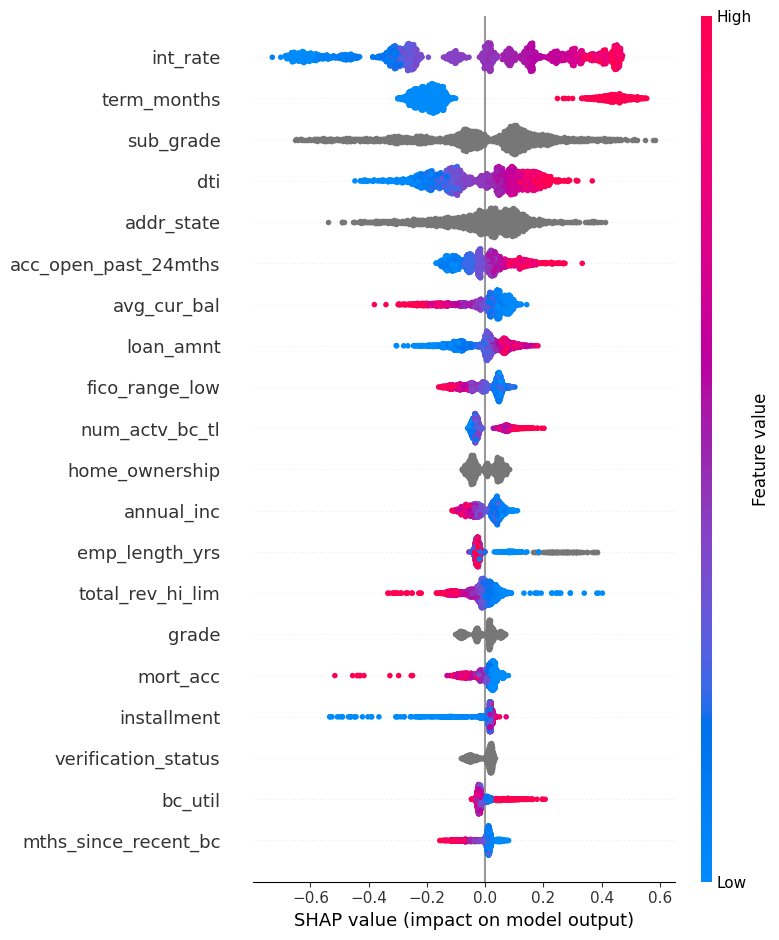

In [16]:
import shap
sample = Xte.sample(2000, random_state=42)
sv = shap.TreeExplainer(final).shap_values(sample)
shap.summary_plot(sv, sample, show=False)
plt.savefig(os.path.join(FIG, "xgb_shap_summary.png"), dpi=150, bbox_inches="tight")
plt.show()